# Analyse Client - Instacart

**Plan du notebook**

| Section | Contenu |
|---|---|
| 0 | Setup (imports, chemins) |
| 1 | Chargement raisonné des 5 fichiers |
| 2 | EDA & contrôle qualité |
| 3 | Table de travail (jointures) |
| 4–8 | Une section par question |
| 9 | Synthèse |

## 0. Setup

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA = Path("Datasets")

pd.set_option("display.max_columns", None)   # ne jamais tronquer les colonnes à l'affichage
sns.set_theme(style="whitegrid")             # style de graphique par défaut

print("pandas", pd.__version__)

pandas 3.0.5


## 1. Chargement raisonné

`order_products.csv` fait **32 millions de lignes**. Si on laisse pandas deviner les types, il met des `int64`
partout (8 octets par nombre) et le texte en `object` : on gaspille ~3× la mémoire nécessaire.

La bonne pratique : **imposer le type de chaque colonne à la lecture** avec `dtype=`.

Règles utilisées ici :
- `int8` : entiers de −128 à 127 → `order_dow` (0–6), `department_id` (1–21), `reordered` (0/1)
- `int16` : jusqu'à ~32 000 → `order_number`, `add_to_cart_order`, `aisle_id`
- `int32` : jusqu'à ~2 milliards → tous les `*_id` volumineux (`order_id`, `user_id`, `product_id`)
- `float32` : `days_since_prior_order` (a des valeurs manquantes → doit être un float)
- `category` : `eval_set` (seulement 3 valeurs distinctes répétées 3,4 M de fois)
- `string` : les libellés texte

Note : `order_hour_of_day` est écrit `"08"` dans le fichier ; demander `int8` suffit, pandas convertit `"08" → 8`.

### 1.1 Les 3 dictionnaires (petits fichiers)

In [73]:
aisles = pd.read_csv(DATA / "aisles.csv", dtype={
    "aisle_id": "int16",
    "aisle": "string",
})

departments = pd.read_csv(DATA / "departments.csv", dtype={
    "department_id": "int8",
    "department": "string",
})

products = pd.read_csv(DATA / "products.csv", dtype={
    "product_id": "int32",
    "product_name": "string",
    "aisle_id": "int16",
    "department_id": "int8",
})

print("aisles     ", aisles.shape)
print("departments", departments.shape)
print("products   ", products.shape)
products.head()

aisles      (134, 2)
departments (21, 2)
products    (49688, 4)


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


### 1.2 Les commandes (`orders`)

In [74]:
orders = pd.read_csv(DATA / "orders.csv", dtype={
    "order_id": "int32",
    "user_id": "int32",
    "eval_set": "category",
    "order_number": "int16",
    "order_dow": "int8",
    "order_hour_of_day": "int8",
    "days_since_prior_order": "float32",
})

print(orders.shape)
print(orders["eval_set"].value_counts())
orders.head()

(3421083, 7)
eval_set
prior    3214874
train     131209
test       75000
Name: count, dtype: int64


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


### 1.3 Le contenu des paniers (`order_products`)

Le gros fichier. Avec les `dtype` ci-dessous : 4 + 4 + 2 + 1 = **11 octets/ligne** → ~350 Mo en RAM.
Sans typage, ce serait ~1 Go. Le chargement peut quelques dizaines de secondes.

In [75]:
order_products = pd.read_csv(DATA / "order_products.csv", dtype={
    "order_id": "int32",
    "product_id": "int32",
    "add_to_cart_order": "int16",
    "reordered": "int8",
})

print(order_products.shape)
order_products.head()

(32434489, 4)


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


### 1.4 Vérification de l'empreinte mémoire

In [76]:
for nom, df in [("aisles", aisles), ("departments", departments), ("products", products),
                ("orders", orders), ("order_products", order_products)]:
    mo = df.memory_usage(deep=True).sum() / 1e6
    print(f"{nom:16} {df.shape[0]:>10,} lignes   {mo:8.1f} Mo")

aisles                  134 lignes        0.0 Mo
departments              21 lignes        0.0 Mo
products             49,688 lignes        4.3 Mo
orders            3,421,083 lignes       58.2 Mo
order_products   32,434,489 lignes      356.8 Mo


## 2. EDA & contrôle qualité

Avant de répondre à une seule question, on vérifie que les données se comportent comme on l'imagine. Trois
familles de vérifications :

1. **Valeurs manquantes** : où, combien, est-ce logique ?
2. **Doublons** : une clé censée être unique (`order_id`, `product_id`) l'est-elle vraiment ?
3. **Cohérence entre tables** : est-ce que les jointures qu'on prévoit de faire vont bien matcher ?

C'est l'étape qu'on est tenté de sauter - et où se cachent les surprises qui faussent tout le reste.

### 2.1 Valeurs manquantes

In [77]:
for nom, df in [("aisles", aisles), ("departments", departments), ("products", products),
                ("orders", orders), ("order_products", order_products)]:
    na = df.isna().sum()
    na = na[na > 0]
    print(f"--- {nom} ---")
    print(na if len(na) else "aucune valeur manquante")
    print()

--- aisles ---
aucune valeur manquante

--- departments ---
aucune valeur manquante

--- products ---
aucune valeur manquante

--- orders ---
days_since_prior_order    206209
dtype: int64

--- order_products ---
aucune valeur manquante



Seule `orders.days_since_prior_order` a des manquants : **206 209**. C'est exactement le nombre de clients
distincts (`user_id`). L'hypothèse à vérifier : ce sont les 1ʳᵉˢ commandes de chaque client (`order_number == 1`),
pour lesquelles il n'existe pas de "commande précédente" - donc le NaN est **normal**, pas une erreur de saisie.

In [78]:
print("n° de clients distincts       :", orders["user_id"].nunique())
print("lignes avec délai manquant    :", orders["days_since_prior_order"].isna().sum())
print("1res commandes (order_number==1):", (orders["order_number"] == 1).sum())

# vérification : le manquant coïncide-t-il EXACTEMENT avec order_number == 1 ?
premiere_commande = orders["order_number"] == 1
delai_manquant = orders["days_since_prior_order"].isna()
print("coïncidence parfaite :", (premiere_commande == delai_manquant).all())

n° de clients distincts       : 206209
lignes avec délai manquant    : 206209
1res commandes (order_number==1): 206209
coïncidence parfaite : True


### 2.2 Doublons sur les clés d'identité

`order_id` doit être unique dans `orders`, `product_id` unique dans `products`. On vérifie.

In [79]:
print("order_id dupliqués dans orders     :", orders["order_id"].duplicated().sum())
print("product_id dupliqués dans products :", products["product_id"].duplicated().sum())
print("aisle_id dupliqués dans aisles     :", aisles["aisle_id"].duplicated().sum())
print("department_id dupliqués            :", departments["department_id"].duplicated().sum())

order_id dupliqués dans orders     : 0
product_id dupliqués dans products : 0
aisle_id dupliqués dans aisles     : 0
department_id dupliqués            : 0


### 2.3 Cohérence entre `orders` et `order_products` - le point le plus important de cette section

Jusqu'ici je t'ai dit qu'`eval_set` valait `prior` / `train` / `test`, et que `test` n'avait pas de contenu de
panier. Vérifions ce qu'il en est **réellement** pour `train` aussi, au lieu de le supposer : quels `eval_set`
sont effectivement présents dans `order_products` ?

In [80]:
ids_avec_panier = order_products["order_id"].unique()
print("order_id distincts dans order_products :", len(ids_avec_panier))

couverture = orders.loc[orders["order_id"].isin(ids_avec_panier), "eval_set"].value_counts()
print("\nÀ quel eval_set appartiennent ces commandes ?")
print(couverture)

order_id distincts dans order_products : 3214874

À quel eval_set appartiennent ces commandes ?
eval_set
prior    3214874
test           0
train          0
Name: count, dtype: int64


**Résultat : `order_products` ne couvre QUE les commandes
`prior`** (3 214 874)  ni `train`, ni évidemment `test`.

Conséquence concrète pour la suite :
- **Q1, Q3, Q5** (qui ont besoin du contenu des paniers) porteront uniquement sur les commandes `prior`.
- **Q2, Q4** (qui ne dépendent que de `orders` : jour/heure, délais) peuvent utiliser tout `orders` sans problème
  puisqu'elles n'ont pas besoin de `order_products`.

## 3. Table de travail (jointures)

But : construire **une** table où chaque ligne = *(un produit dans une commande)*, enrichie avec le nom du
produit, son rayon, son département, et les infos de la commande (client, jour, heure). C'est la table qu'on
réutilisera pour Q1, Q3 et Q5.

On procède en 3 jointures successives, en vérifiant après **chacune** que le nombre de lignes ne bouge pas
(sinon ça veut dire qu'une clé n'est pas unique côté droit, et le `merge` a dupliqué des lignes).

Rappel de la Section 2 : on part de `order_products`, qui ne couvre que les commandes `prior`.

### 3.1 Enrichir les produits (rayon + département)

On assemble d'abord le petit dictionnaire `produits` : `products` + nom du rayon + nom du département.
Ces 3 tables sont petites (< 50 000 lignes), la mémoire n'est pas un enjeu ici.

In [81]:
produits = (
    products
    .merge(aisles, on="aisle_id", how="left")
    .merge(departments, on="department_id", how="left")
)

print("avant :", products.shape[0], "lignes  -  après jointures :", produits.shape[0], "lignes")
print("NA introduits :", produits[["aisle", "department"]].isna().sum().to_dict())
produits.head(3)

avant : 49688 lignes  -  après jointures : 49688 lignes
NA introduits : {'aisle': 0, 'department': 0}


,product_id,product_name,aisle_id,department_id,aisle,department
0,1,Chocolate Sandwich Cookies,61,19,cookies cakes,snacks
1,2,All-Seasons Salt,104,13,spices seasonings,pantry
2,3,Robust Golden Unsweetened Oolong Tea,94,7,tea,beverages


### 3.2 Construire `paniers` : `order_products` + infos produit

C'est ici que la mémoire devient un vrai sujet : la table finale aura **32,4 M de lignes**. Si `product_name`,
`aisle`, `department` restent en texte libre (`string`), chaque ligne recopie une chaîne de caractères → des
centaines de Mo gaspillés, alors qu'il n'existe que 49 688 / 134 / 21 valeurs distinctes.

On force donc ces 3 colonnes en `category` juste après la jointure : pandas ne stocke la chaîne qu'une fois,
et remplace chaque ligne par un simple code entier vers cette valeur.

In [82]:
paniers = order_products.merge(
    produits[["product_id", "product_name", "aisle", "department"]],
    on="product_id", how="left",
)

for col in ["product_name", "aisle", "department"]:
    paniers[col] = paniers[col].astype("category")

print("avant :", order_products.shape[0], " après :", paniers.shape[0], "  (doit être identique)")
print("NA product_name :", paniers["product_name"].isna().sum())
paniers.head(3)

avant : 32434489  après : 32434489   (doit être identique)
NA product_name : 0


,order_id,product_id,add_to_cart_order,reordered,product_name,aisle,department
0,2,33120,1,1,Organic Egg Whites,eggs,dairy eggs
1,2,28985,2,1,Michigan Organic Kale,fresh vegetables,produce
2,2,9327,3,0,Garlic Powder,spices seasonings,pantry


### 3.3 Ajouter les infos de commande (client, jour, heure)

On rattache `user_id`, `order_number`, `order_dow`, `order_hour_of_day`, `days_since_prior_order` depuis
`orders`. On restreint d'abord `orders` aux commandes `prior` (les seules présentes dans `paniers`) et on
retire `eval_set`, devenue inutile puisqu'elle vaudra `prior` partout.

In [83]:
orders_prior = orders.loc[orders["eval_set"] == "prior"].drop(columns=["eval_set"])

paniers = paniers.merge(
    orders_prior[["order_id", "user_id", "order_number", "order_dow",
                   "order_hour_of_day", "days_since_prior_order"]],
    on="order_id", how="left",
)

print("lignes :", paniers.shape[0], "  colonnes :", paniers.shape[1])
print("NA user_id :", paniers["user_id"].isna().sum(), "(doit être 0, sinon une commande n'a pas été retrouvée)")
paniers.head(3)

lignes : 32434489   colonnes : 12
NA user_id : 0 (doit être 0, sinon une commande n'a pas été retrouvée)


,order_id,product_id,add_to_cart_order,reordered,product_name,aisle,department,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2,33120,1,1,Organic Egg Whites,eggs,dairy eggs,202279,3,5,9,8.0
1,2,28985,2,1,Michigan Organic Kale,fresh vegetables,produce,202279,3,5,9,8.0
2,2,9327,3,0,Garlic Powder,spices seasonings,pantry,202279,3,5,9,8.0


### 3.4 Bilan de la table de travail

In [84]:
print(paniers.dtypes)
print("\nmémoire :", round(paniers.memory_usage(deep=True).sum() / 1e6, 1), "Mo")
print("commandes distinctes :", paniers["order_id"].nunique())
print("clients distincts    :", paniers["user_id"].nunique())

order_id                     int32
product_id                   int32
add_to_cart_order            int16
reordered                     int8
product_name              category
aisle                     category
department                category
user_id                      int32
order_number                 int16
order_dow                     int8
order_hour_of_day             int8
days_since_prior_order     float32
dtype: object

mémoire : 977.0 Mo
commandes distinctes : 3214874
clients distincts    : 206209


## 4. Q1 - Combien d'articles les clients commandent-ils par commande ?

**Donnée** : dans `paniers`, une ligne = un produit dans une commande → le nombre d'articles d'une commande
est simplement le **nombre de lignes** qui partagent le même `order_id`.

**Calcul** : `groupby("order_id").size()` donne une valeur (la taille) par commande. On regarde ensuite sa
distribution (`describe`, médiane, mode).

**Piège à anticiper** : la distribution est asymétrique à droite (quelques paniers énormes) → la moyenne sera
tirée vers le haut. On retient la **médiane** comme réponse principale, pas la moyenne seule.

In [85]:
taille_panier = paniers.groupby("order_id").size()

print("nombre de commandes :", len(taille_panier))
taille_panier.describe()

nombre de commandes : 3214874


count    3.214874e+06
mean     1.008888e+01
std      7.525398e+00
min      1.000000e+00
25%      5.000000e+00
50%      8.000000e+00
75%      1.400000e+01
max      1.450000e+02
dtype: float64

In [86]:
print("moyenne :", round(taille_panier.mean(), 2))
print("médiane :", taille_panier.median())
print("mode    :", taille_panier.mode().iloc[0])

moyenne : 10.09
médiane : 8.0
mode    : 5


### Visualisation

On choisi un histograme car on veut voir la **forme** de la distribution d'une variable numérique
(pas comparer des catégories, pas suivre une évolution dans le temps).

On coupe l'axe à 40 articles : au-delà, il y a très peu de commandes et ça écraserait le graphique sans
apporter d'information.

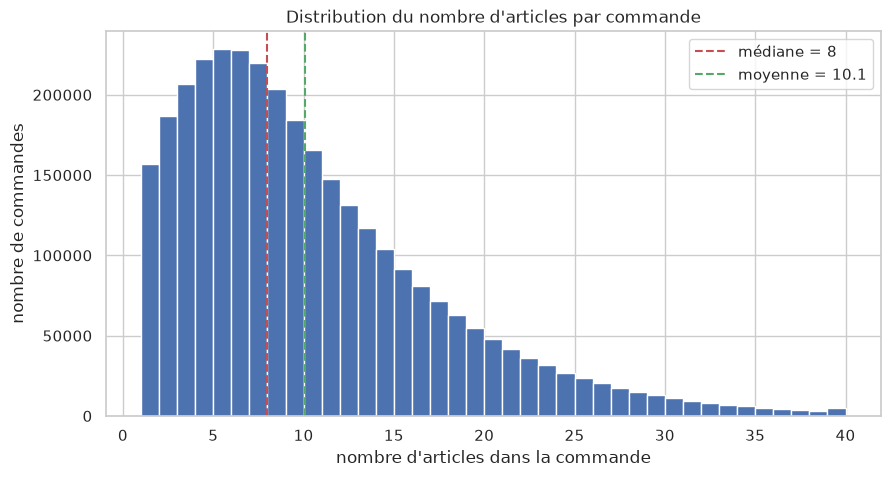

In [87]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(taille_panier, bins=range(1, 41), color="#4C72B0", edgecolor="white")
ax.axvline(taille_panier.median(), color="#C44E52", linestyle="--", label=f"médiane = {taille_panier.median():.0f}")
ax.axvline(taille_panier.mean(), color="#55A868", linestyle="--", label=f"moyenne = {taille_panier.mean():.1f}")
ax.set_xlabel("nombre d'articles dans la commande")
ax.set_ylabel("nombre de commandes")
ax.set_title("Distribution du nombre d'articles par commande")
ax.legend()
plt.show()

### Conclusion Q1

Le graphique montre que les clients ont en moyenne 10 articles dans leurs paniers de commande; avec une médiane à 8 articles.

## 5. Q2 - Quand les clients commandent-ils (jour × heure) ?

**Donnée** : `orders` seul suffit - `order_dow` (jour, 0–6) et `order_hour_of_day` (heure, 0–23). Pas besoin
de `paniers` (rappel Section 2.3 : cette question ne dépend pas du contenu des commandes).

**Calcul** : `groupby(["order_dow","order_hour_of_day"]).size()` compte les commandes pour chaque combinaison
jour/heure, puis `.unstack()` transforme le résultat en tableau 7×24 (une matrice croisant les deux axes).

**Visualisation** : une **heatmap** - c'est le bon choix dès qu'on croise 2 variables catégorielles avec une
intensité à comparer. En complément, deux graphiques simples pour lire chaque axe isolément.

**Piège** : Instacart ne documente pas quel entier (0–6) correspond à quel jour réel de la semaine. On garde
donc des libellés neutres "Jour 0" à "Jour 6" plutôt que de deviner "lundi/mardi/...".

In [88]:
matrice_jour_heure = orders.groupby(["order_dow", "order_hour_of_day"]).size().unstack(fill_value=0)

print(matrice_jour_heure.shape, "(7 jours x 24 heures)")
matrice_jour_heure

(7, 24) (7 jours x 24 heures)


order_hour_of_day,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
order_dow,,,,,,,,,,,,,,,,,,,,,,,,
0,3936,2398,1409,963,813,1168,3329,12410,28108,40798,48465,51035,51443,53849,54552,53954,49463,39753,29572,22654,18277,14423,11246,6887
1,3674,1830,1105,748,809,1607,5370,16571,34116,51908,55671,51584,47079,46728,46764,46403,44761,36792,28977,22145,16281,11943,8992,5620
2,3059,1572,943,719,744,1399,4758,13245,24635,36314,39230,38128,35780,36650,37173,37469,37541,32151,26470,20084,15039,10653,8146,5358
3,2952,1495,953,654,719,1355,4562,12396,22553,32312,36040,35215,33455,34161,34773,35990,35273,30368,25001,19249,13795,10278,8242,5181
4,2642,1512,899,686,730,1330,4401,12493,21814,31409,35034,33857,32249,32751,33625,34222,34093,29378,24425,19350,14186,10796,8812,5645
5,3189,1672,1016,841,910,1574,4866,13434,24015,34232,38313,37915,35714,36296,37407,37508,35860,29955,24310,18741,13322,9515,7498,5265
6,3306,1919,1214,863,802,1136,3243,11319,22960,30839,35665,36994,37121,37564,38748,38093,35562,30398,24157,18346,13392,10501,8532,6087


### Heatmap jour × heure

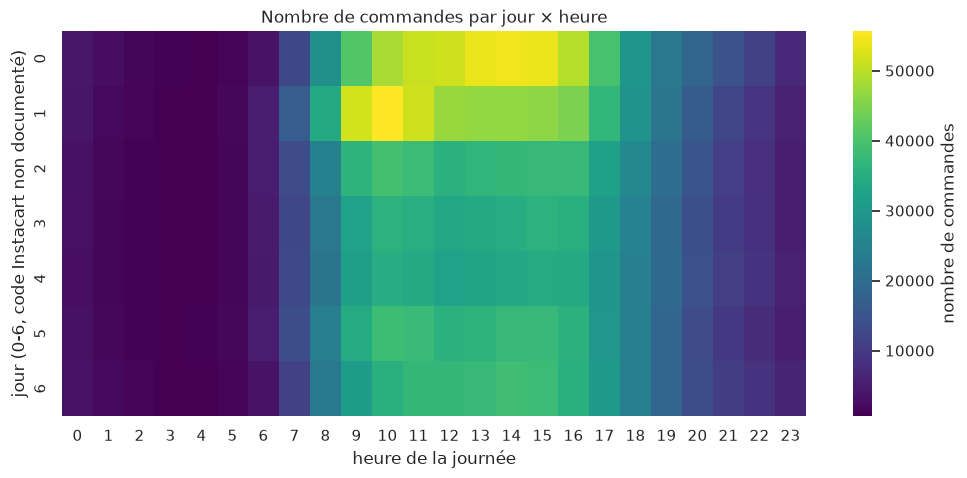

In [89]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(matrice_jour_heure, cmap="viridis", ax=ax, cbar_kws={"label": "nombre de commandes"})
ax.set_xlabel("heure de la journée")
ax.set_ylabel("jour (0-6, code Instacart non documenté)")
ax.set_title("Nombre de commandes par jour × heure")
plt.show()

### Lecture de chaque axe séparément

La heatmap montre le croisement, mais deux barplots simples permettent de comparer plus précisément les jours
entre eux, et les heures entre elles.

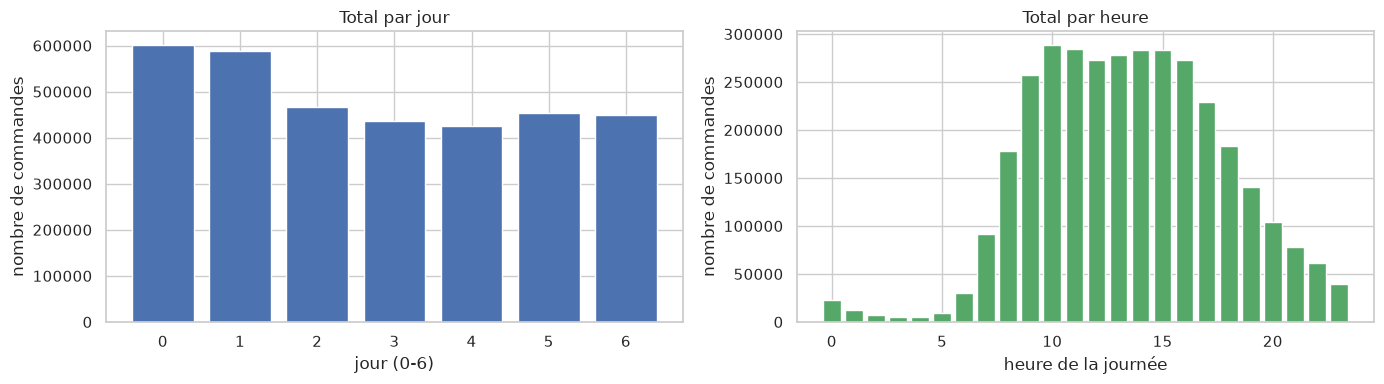

In [90]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

commandes_par_jour = orders["order_dow"].value_counts().sort_index()
axes[0].bar(commandes_par_jour.index, commandes_par_jour.values, color="#4C72B0")
axes[0].set_xlabel("jour (0-6)")
axes[0].set_ylabel("nombre de commandes")
axes[0].set_title("Total par jour")
axes[0].set_xticks(range(7))

commandes_par_heure = orders["order_hour_of_day"].value_counts().sort_index()
axes[1].bar(commandes_par_heure.index, commandes_par_heure.values, color="#55A868")
axes[1].set_xlabel("heure de la journée")
axes[1].set_ylabel("nombre de commandes")
axes[1].set_title("Total par heure")

plt.tight_layout()
plt.show()

### Conclusion Q2
Les graphiques montrent une forte hausse de commandes vers 7h du matin jusqu'a 16h. Les donnés fournies montrent que cette concentration a lieu entre les jours 0 et 1 mais rien ne pemret de confirmer quels jours de la semaine il s'agit. On peut toutefois associer ce pattern à une tendance de fin de semaine soit samedi et dimanche.

## 6. Q3 - Quel produit est ajouté en premier / en dernier au panier ?

**Donnée** : `paniers`, colonne `add_to_cart_order` (1 = premier produit ajouté à la commande).

**Calcul** :
- "premier" = les lignes où `add_to_cart_order == 1` → un simple filtre.
- "dernier" = pour chaque `order_id`, la ligne où `add_to_cart_order` est **maximal**. On trie par
  `(order_id, add_to_cart_order)` puis on prend la dernière ligne de chaque groupe (`groupby().tail(1)`).

Dans les deux cas on compte ensuite les occurrences par produit (`value_counts`) et on garde le top 15.

**Piège anticipé** : les produits les plus vendus au global (bananes…) vont dominer les deux classements,
juste parce qu'ils sont dans énormément de paniers - pas parce qu'on les met "spécifiquement" en premier ou en
dernier. On complètera donc avec un indicateur de **proportion** : sur toutes les fois où un produit apparaît,
quelle part du temps est-il posé en premier ? Ça fait ressortir des produits différents.

### 6.1 Top 15 des produits ajoutés en premier

In [91]:
premiers = paniers.loc[paniers["add_to_cart_order"] == 1]
top_premiers = premiers["product_name"].value_counts().head(15)

print("nb de commandes couvertes :", len(premiers), "(doit être = nb de commandes)")
top_premiers

nb de commandes couvertes : 3214874 (doit être = nb de commandes)


product_name
Banana                        110916
Bag of Organic Bananas         78988
Organic Whole Milk             30927
Organic Strawberries           27975
Organic Hass Avocado           24116
Organic Baby Spinach           23543
Organic Avocado                22398
Spring Water                   16822
Strawberries                   16366
Organic Raspberries            14393
Sparkling Water Grapefruit     13733
Organic Half & Half            12676
Large Lemon                    12316
Soda                           11770
Organic Reduced Fat Milk        9885
Name: count, dtype: int64

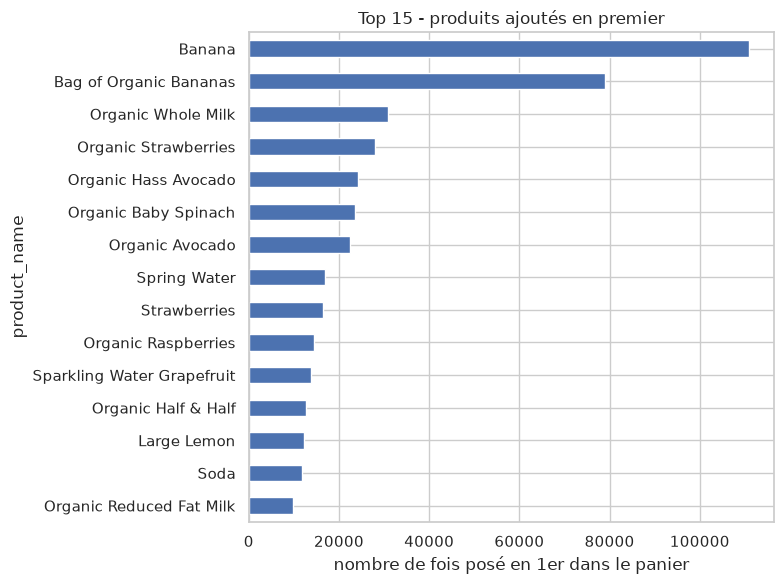

In [92]:
fig, ax = plt.subplots(figsize=(8, 6))
top_premiers.sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("nombre de fois posé en 1er dans le panier")
ax.set_title("Top 15 - produits ajoutés en premier")
plt.tight_layout()
plt.show()

### 6.2 Top 15 des produits ajoutés en dernier

Plus coûteux à calculer : il faut d'abord trouver, **par commande**, quelle ligne a le plus grand
`add_to_cart_order`. On trie la table par `order_id` puis `add_to_cart_order` croissant, et on prend la
dernière ligne de chaque groupe `order_id` - cette cellule prend une vingtaine de secondes, c'est normal
(on manipule les 32 M de lignes).

In [93]:
colonnes_utiles = paniers[["order_id", "add_to_cart_order", "product_name"]]
derniers = colonnes_utiles.sort_values(["order_id", "add_to_cart_order"]).groupby("order_id", sort=False).tail(1)
top_derniers = derniers["product_name"].value_counts().head(15)

print("nb de commandes couvertes :", len(derniers), "(doit être = nb de commandes)")
top_derniers

nb de commandes couvertes : 3214874 (doit être = nb de commandes)


product_name
Banana                    30098
Bag of Organic Bananas    29826
Organic Strawberries      23477
Organic Baby Spinach      21733
Organic Hass Avocado      15544
Strawberries              15529
Organic Avocado           12546
Large Lemon               11883
Organic Blueberries       11347
Organic Whole Milk        11003
Limes                     10405
Organic Raspberries        9782
Spring Water               8715
Organic Zucchini           8375
Soda                       8363
Name: count, dtype: int64

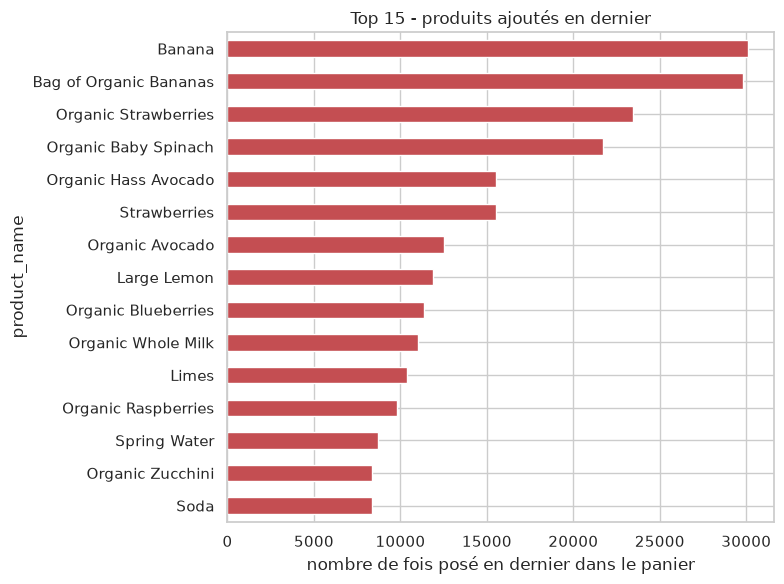

In [94]:
fig, ax = plt.subplots(figsize=(8, 6))
top_derniers.sort_values().plot.barh(ax=ax, color="#C44E52")
ax.set_xlabel("nombre de fois posé en dernier dans le panier")
ax.set_title("Top 15 - produits ajoutés en dernier")
plt.tight_layout()
plt.show()

### 6.3 Corriger le biais de popularité

Les deux tops précédents sont sans doute dominés par les mêmes produits (bananes, avocats…), simplement parce
qu'ils sont dans un très grand nombre de commandes. Ça ne dit rien sur si on les met *spécifiquement* en
premier plus souvent que la moyenne.

**Nouvel indicateur** : pour chaque produit, `part_en_premier = (nb de fois en 1er) / (nb total d'apparitions)`.
Un produit apparu 100 fois et posé en 1er 40 fois (40 %) est plus "typiquement posé en premier" qu'un produit
apparu 100 000 fois et posé en 1er 10 000 fois (10 %), même si ce dernier a un total brut plus élevé.

On filtre sur les produits ayant au moins 1000 apparitions, pour éviter qu'un produit vu 3 fois et posé 3 fois
en 1er (100 %) fausse le classement par pur hasard statistique.

In [95]:
total_par_produit = paniers["product_name"].value_counts()
premier_par_produit = premiers["product_name"].value_counts()

produits_frequents = total_par_produit[total_par_produit >= 1000].index

part_en_premier = (
    premier_par_produit.reindex(produits_frequents, fill_value=0)
    / total_par_produit.reindex(produits_frequents)
).sort_values(ascending=False)

top_part_en_premier = part_en_premier.head(15)
top_part_en_premier

product_name
Water Mineral                       0.468360
Sparkling Water, Bottles            0.439589
White Multifold Towels              0.432397
Organic Low Fat Milk                0.405072
Drinking Water                      0.402739
Cookie Tray                         0.394541
2% Lactose Free Milk                0.387060
Seltzer Water                       0.360508
80  Vodka Holiday Edition           0.358611
Vodka                               0.355251
Mineral Water                       0.354279
XL Pick-A-Size Paper Towel Rolls    0.354201
Smartwater                          0.346227
Ice                                 0.345194
Iced Coffee                         0.337000
Name: count, dtype: float64

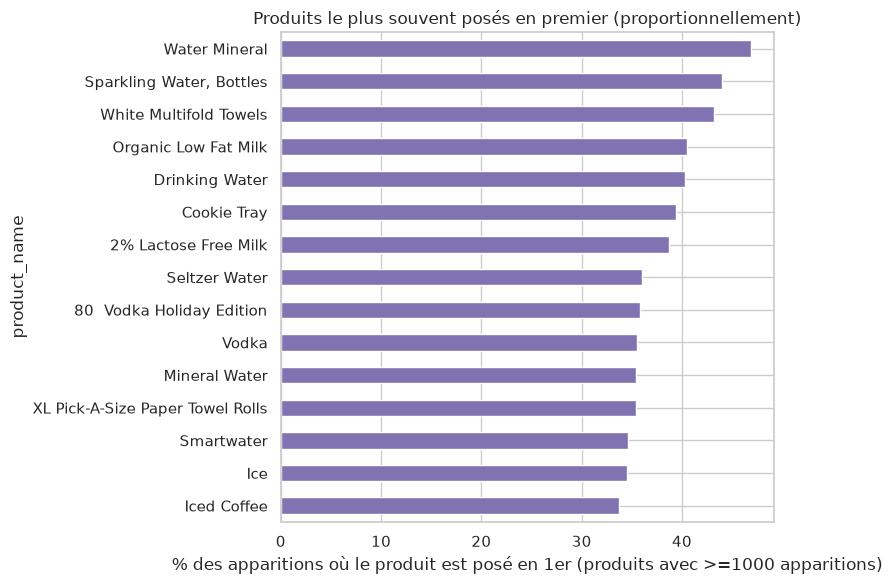

In [96]:
fig, ax = plt.subplots(figsize=(8, 6))
(top_part_en_premier.sort_values() * 100).plot.barh(ax=ax, color="#8172B2")
ax.set_xlabel("% des apparitions où le produit est posé en 1er (produits avec >=1000 apparitions)")
ax.set_title("Produits le plus souvent posés en premier (proportionnellement)")
plt.tight_layout()
plt.show()

### 6.4 Même correction pour "dernier"

Exactement le même raisonnement que 6.3, côté "dernier" cette fois : `part_en_dernier = (nb de fois en dernier)
/ (nb total d'apparitions)`. `derniers` (calculé en 6.2) contient déjà, pour chaque commande, la ligne du
produit posé en dernier - on en tire les comptes complets par produit (pas juste le top 15 vu plus haut).

In [97]:
dernier_par_produit = derniers["product_name"].value_counts()

part_en_dernier = (
    dernier_par_produit.reindex(produits_frequents, fill_value=0)
    / total_par_produit.reindex(produits_frequents)
).sort_values(ascending=False)

top_part_en_dernier = part_en_dernier.head(15)
top_part_en_dernier

product_name
XL Pick-A-Size Paper Towel Rolls                                    0.444811
Cookie Tray                                                         0.400331
Red Plastic Cups                                                    0.382465
Wint-O-Green                                                        0.381290
White Multifold Towels                                              0.380797
Tall Kitchen Bag With Febreze Odor Shield                           0.380488
Drinking Water                                                      0.367203
Fabric Softener Dryer Sheet Outdoor Fresh 160CT Fabric Enhancers    0.362929
Organic Sweet Cherries                                              0.343462
Non-Scratch Scrub Sponges                                           0.339548
All Natural White Vinegar                                           0.338941
Heavy Duty Scrub Sponge                                             0.338323
Organic Virgin Coconut Oil                                     

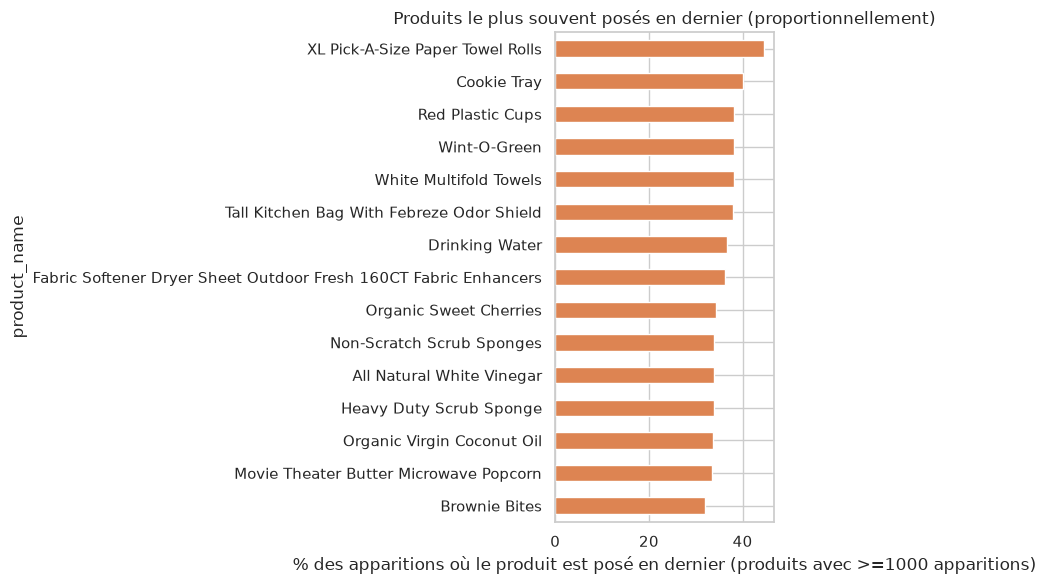

In [98]:
fig, ax = plt.subplots(figsize=(8, 6))
(top_part_en_dernier.sort_values() * 100).plot.barh(ax=ax, color="#DD8452")
ax.set_xlabel("% des apparitions où le produit est posé en dernier (produits avec >=1000 apparitions)")
ax.set_title("Produits le plus souvent posés en dernier (proportionnellement)")
plt.tight_layout()
plt.show()

### Conclusion Q3

Les deux premiers graphiques ne sont pas représentatifs de l'ordre des articles car leurs positions dans le classement peut aussi s'expliquer par le simple fait qu'ils sont populaires et donc souvent présent dans un panier. POur palier à ce billet, on prends en compte le nombre d'apparition du produit dans le panier. Les tops en proportion se recoupent fortement entre premier et dernier, et concernent des produits lourds/non périssables plutôt que les produits les plus populaires, ce qui suggère que ces articles sont ajoutés aux extrémités de la commande plutôt qu'au hasard, sans qu'on puisse expliquer pourquoi avec ces seules données.

## 7. Q4 - À quelle fréquence un client repasse-t-il commande ?

**Donnée** : `orders` seul suffit (rappel Section 2.3) - deux angles distincts pour cette question :
1. **Combien de commandes au total** par client → `order_number` (le rang de chaque commande pour un client donné).
2. **Combien de jours entre deux commandes** → `days_since_prior_order`, déjà présent directement dans les données.

**Calcul** :
- Nb de commandes par client : `groupby("user_id")["order_number"].max()` (le rang de la dernière commande =
  le nombre total de commandes, puisque `order_number` est une séquence 1, 2, 3…).
- Délai entre commandes : on prend directement la colonne `days_since_prior_order` (en excluant les `NaN`,
  qui sont les 1ʳᵉˢ commandes sans délai - vu en Section 2.1), et on regarde sa distribution globale.

**Piège à anticiper** : `days_since_prior_order` est **plafonné à 30** dans ce jeu de données - toute valeur
réelle ≥ 30 jours est enregistrée comme "30". On va vérifier ça concrètement : si beaucoup de lignes valent
exactement 30, c'est le signe d'un plafond (censure), pas d'un vrai pic de comportement à 30 jours pile.

### 7.1 Nombre de commandes par client

In [99]:
nb_commandes = orders.groupby("user_id")["order_number"].max()

print("nombre de clients :", len(nb_commandes))
nb_commandes.describe()

nombre de clients : 206209


count    206209.000000
mean         16.590367
std          16.654774
min           4.000000
25%           6.000000
50%          10.000000
75%          20.000000
max         100.000000
Name: order_number, dtype: float64

Remarque à vérifier en exécutant la cellule au-dessus : le **minimum devrait être 4**, pas 1. Ce n'est pas un
bug - Instacart n'a inclus dans ce jeu de données que des clients ayant passé **au moins 4 commandes**
(une décision de constitution du dataset, pas un comportement réel). Bon réflexe à garder : un minimum "trop
rond" ou "trop élevé" pour être un hasard mérite toujours une explication avant de continuer.

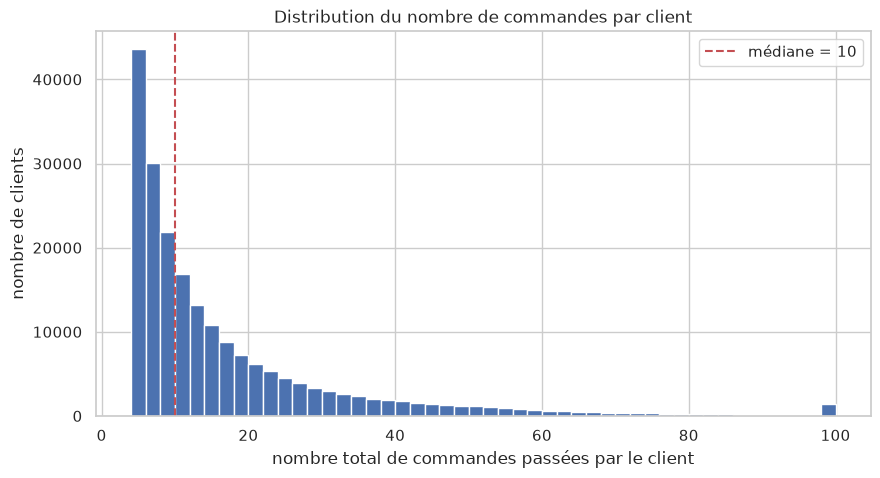

In [100]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(nb_commandes, bins=range(4, 102, 2), color="#4C72B0", edgecolor="white")
ax.axvline(nb_commandes.median(), color="#C44E52", linestyle="--", label=f"médiane = {nb_commandes.median():.0f}")
ax.set_xlabel("nombre total de commandes passées par le client")
ax.set_ylabel("nombre de clients")
ax.set_title("Distribution du nombre de commandes par client")
ax.legend()
plt.show()

### 7.2 Délai entre deux commandes

On exclut les `NaN` (1ʳᵉˢ commandes, sans commande précédente) avant de regarder la distribution.

In [101]:
delais = orders["days_since_prior_order"].dropna()

print("nombre de délais observés :", len(delais))
delais.describe()

nombre de délais observés : 3214874


count    3.214874e+06
mean     1.111484e+01
std      9.206737e+00
min      0.000000e+00
25%      4.000000e+00
50%      7.000000e+00
75%      1.500000e+01
max      3.000000e+01
Name: days_since_prior_order, dtype: float64

In [102]:
print("part des délais exactement égaux à 30 :", round((delais == 30).mean() * 100, 1), "%")
print("part des délais exactement égaux à 7  :", round((delais == 7).mean() * 100, 1), "%")

part des délais exactement égaux à 30 : 11.5 %
part des délais exactement égaux à 7  : 10.0 %


11 % des délais collés pile à 30 (bien plus que n'importe quelle autre valeur isolée) : c'est
la confirmation du plafond. On devrait aussi voit un pic net à 7 jours : ça, c'est un vrai signal ; un **rythme
hebdomadaire** de commande (les gens qui recommandent "à la semaine").

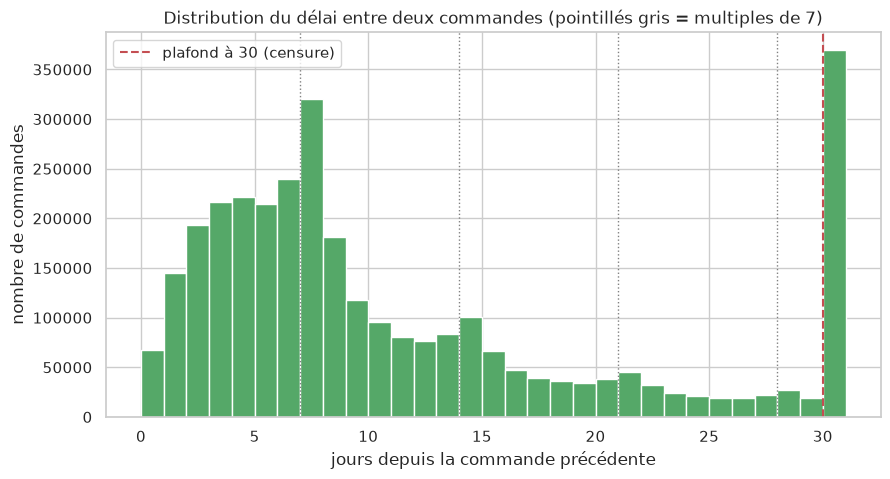

In [103]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(delais, bins=range(0, 32), color="#55A868", edgecolor="white")
for j in [7, 14, 21, 28]:
    ax.axvline(j, color="grey", linestyle=":", linewidth=1)
ax.axvline(30, color="#C44E52", linestyle="--", label="plafond à 30 (censure)")
ax.set_xlabel("jours depuis la commande précédente")
ax.set_ylabel("nombre de commandes")
ax.set_title("Distribution du délai entre deux commandes (pointillés gris = multiples de 7)")
ax.legend()
plt.show()

### Conclusion Q4

Un client passe en moyenne 16,6 commandes (médiane à 10) - l'écart entre les deux montre qu'une minorité de
gros clients très fidèles tire la moyenne vers le haut, comme pour la taille du panier en Q1. Le minimum est 4
et non 1 : Instacart n'a gardé dans ce jeu de données que des clients ayant déjà passé au moins 4 commandes,
donc cette analyse porte sur des clients déjà relativement engagés, pas sur l'ensemble de la clientèle réelle.

Le délai médian entre deux commandes est de 7 jours (moyenne 11,1, tirée vers le haut par les gros délais).
Le pic à 30 jours (11,5 % des délais, largement au-dessus de toute autre valeur isolée) n'est pas un vrai
comportement : c'est un plafond de mesure - Instacart enregistre "30" pour tout délai réel de 30 jours ou plus,
donc ce pic mélange en réalité des clients revenus à 30, 45, ou 90 jours. Le pic à 7 jours (10 %), en revanche,
est un vrai signal : une part importante des clients recommande selon un **rythme hebdomadaire** régulier -
plus visible encore sur l'histogramme avec les échos à 14 et 21 jours (multiples de 7), qui suggèrent que même
les clients moins fréquents gardent un rythme calé sur la semaine plutôt qu'aléatoire.